Customer Segmentation Using ID3 Decision Trees

Step 1: Load and Preprocess the Retail Dataset into RFM Features

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Create a robust synthetic sample representing the Online Retail data structure
np.random.seed(42)
n_samples = 800
data = {
'Recency_Tier': np.random.choice(['Recent', 'Dormant', 'At-Risk'], n_samples, p=[0.5, 0.3,
0.2]),
'Frequency_Tier': np.random.choice(['Low', 'Medium', 'High'], n_samples, p=[0.4, 0.4, 0.2]),
'Monetary_Tier': np.random.choice(['Low', 'Medium', 'High'], n_samples, p=[0.3, 0.5, 0.2]),
'Segment': np.random.choice(['Bronze', 'Silver', 'Gold'], n_samples, p=[0.4, 0.4, 0.2])
}
df = pd.DataFrame(data)
# Map discrete string categoricals into encoded integers for algorithm compatibility
for col in ['Recency_Tier', 'Frequency_Tier', 'Monetary_Tier']:
    df[col] = df[col].astype('category').cat.codes
# Define map for targets
target_map = {'Bronze': 0, 'Silver': 1, 'Gold': 2}
df['Segment'] = df['Segment'].map(target_map)
X = df.drop('Segment', axis=1)
y = df['Segment']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(df.head())

   Recency_Tier  Frequency_Tier  Monetary_Tier  Segment
0             2               2              1        0
1             0               1              2        0
2             1               2              1        1
3             1               2              2        0
4             2               2              1        1


Step 2: Train the Decision Tree Model Using Entropy Criteria (ID3 Mode)

In [ ]:
# Sklearn uses an optimized CART layout; enforcing criterion='entropy' mimics the splitting choice logic of ID3
# max_depth limits tree growth to ensure clear interpretability during evaluation stages
clf_tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf_tree.fit(X_train, y_train)
y_pred = clf_tree.predict(X_test)
print(f'Model Classification Accuracy: {accuracy_score(y_test, y_pred):.4f}')

Model Classification Accuracy: 0.3800


Step 3: Structural Tree Visualization and Feature Importance Analysis

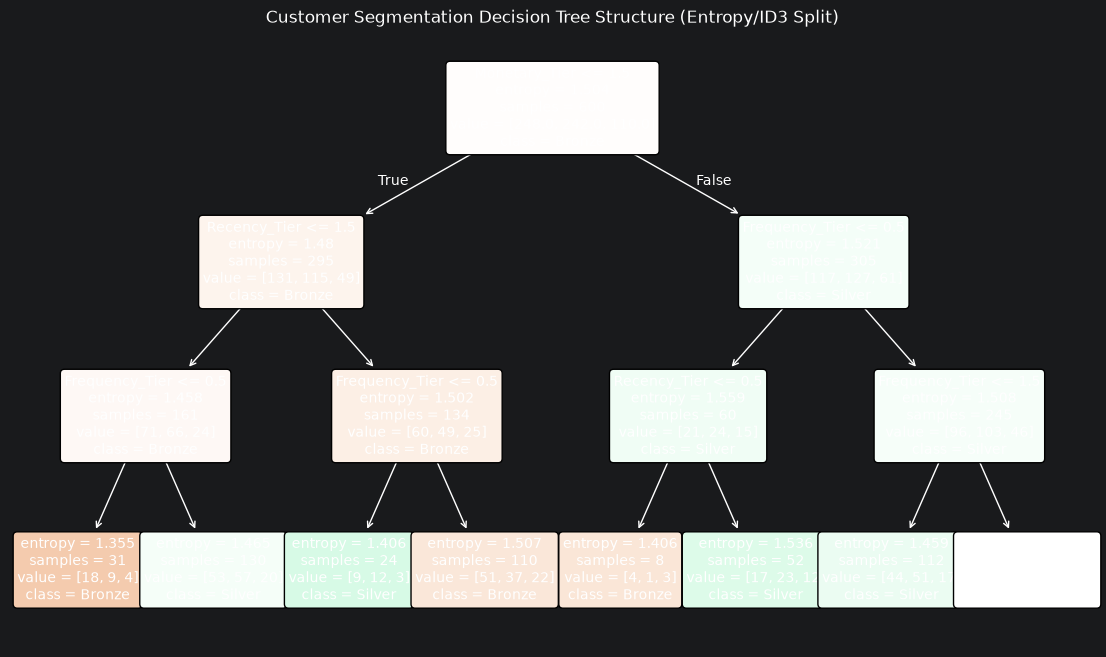

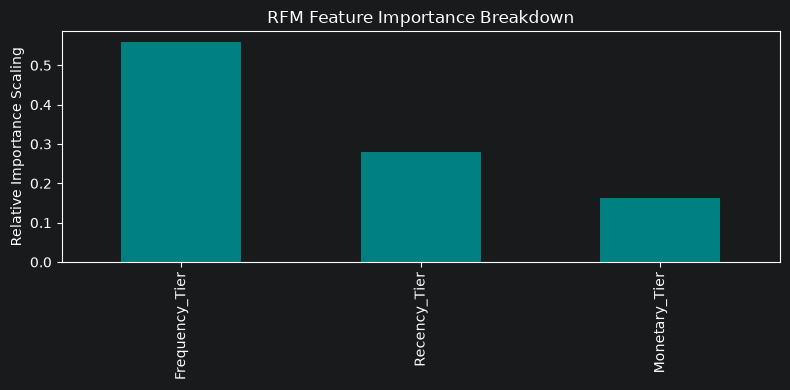


Feature Importance Metrics:
 Frequency_Tier    0.558495
Recency_Tier      0.278810
Monetary_Tier     0.162695
dtype: float64


In [ ]:
# Visualize tree structure path arrays
plt.figure(figsize=(14, 8))
plot_tree(clf_tree,
    feature_names=list(X.columns),
    class_names=['Bronze', 'Silver', 'Gold'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Customer Segmentation Decision Tree Structure (Entropy/ID3 Split)')
plt.show()
# Extract, sort, and display computed Gini/Entropy Feature Importances
importances = clf_tree.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
feat_imp.plot(kind='bar', color='teal')
plt.ylabel('Relative Importance Scaling')
plt.title('RFM Feature Importance Breakdown')
plt.tight_layout()
plt.show()
print('\nFeature Importance Metrics:\n', feat_imp)